# GARCÍA HERNÁNDEZ RODRIGO | 23070447
# ANÁLISIS DE LIBROS 

AÑADIR LEMATIZACIÓN Y STEMMING 

# ÍNDICE

1. [Importar librerías](#1-importar-librerías)
2. [Recolección de datos](#2-recolección-de-datos)
3. [Contar total de palabras](#3-contar-total-de-palabras)
4. [Análisis de sentimientos con Vader](#4-análisis-de-sentimientos-con-vader)
5. [Palabras positivas y negativas](#5-palabras-positivas-y-negativas)
6. [Gráfica palabras positivas y negativas](#6-gráfica-palabras-positivas-y-negativas)
7. [Gráfica palabras positivas y negativas](#7-gráfica-palabras-positivas-y-negativas)
8. [Tokenización y filtrado de stopwords en español](#8-tokenización-y-filtrado-de-stopwords-en-español)
9. [STEMMING](#9-stemming)
10. [Lematización](#10-lematización)
11. [Dataframe final](#11-dataframe-final)

# 1. Importar librerias

In [2]:
import urllib.request
import re
import string
from collections import Counter
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.sentiment.vader import SentimentIntensityAnalyzer

import re
from collections import Counter
import matplotlib.pyplot as plt
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

nltk.download('vader_lexicon', quiet=True)

True

# 2. Recolección de datos

In [4]:
ARCHIVO = "/kaggle/input/datasets/rodrigogarciah/leyendallorona/la llorona.txt"

# Leer el archivo
with open(ARCHIVO, "r", encoding="utf-8") as f:
    texto = f.read()

# 3. Contar total de palabras

In [8]:
palabras = re.findall(r"\b\w+\b", texto, flags=re.UNICODE)
total_palabras = len(palabras)

print(f"Total de palabras del libro: {total_palabras}")

Total de palabras del libro: 601


# 4. Análisis de sentimientos con Vader

In [9]:
# ---------------------------------------------------------
# 2. Análisis de sentimiento con VADER
# ---------------------------------------------------------
sia = SentimentIntensityAnalyzer()

# Sentimiento global del texto completo
score_global = sia.polarity_scores(texto)
print("\nSentimiento global del texto:")
print(score_global)

# Análisis por oraciones
oraciones = re.split(r'(?<=[.!?…])\s+', texto)
resultados = []

for i, oracion in enumerate(oraciones, 1):
    if oracion.strip():
        scores = sia.polarity_scores(oracion)
        resultados.append((i, oracion.strip(), scores))

print("\nPrimeras 10 oraciones analizadas:")
for i, oracion, scores in resultados[:10]:
    print(f"{i:03d} | compound={scores['compound']:+.3f} | {oracion[:90]}...")

# Promedio compound
if resultados:
    promedio = sum(s['compound'] for _, _, s in resultados) / len(resultados)
    print(f"\nCompound promedio por oración: {promedio:.3f}")


Sentimiento global del texto:
{'neg': 0.047, 'neu': 0.953, 'pos': 0.0, 'compound': -0.9724}

Primeras 10 oraciones analizadas:
001 | compound=+0.000 | Leyenda mexicana: La llorona
Hace muchos, muchísimos años, en una ciudad mexicana llamada ...
002 | compound=+0.000 | ¡Dónde están mis hijooooos!”…decía una y otra vez....
003 | compound=-0.359 | Aquellos lamentos eran muy extraños y quitaban el sueño a los habitantes de la zona, hasta...
004 | compound=+0.000 | ¡No podemos dormir!- Gritaba un vecino una mañana al encontrarse con otro vecino....
005 | compound=-0.296 | No eres el único, yo estoy igual, y dicen que todo el mundo se encierra a cal y canto cuan...
006 | compound=+0.000 | Respondió el otro....
007 | compound=+0.000 | Como los rumores en los pueblos y las ciudades eran muy habituales antaño, se decía que aq...
008 | compound=-0.700 | Otros iban más allá y se atrevían a asegurar que la misteriosa mujer no caminaba, sino que...
009 | compound=-0.296 | Pero no solo eso, porque 

# 5. palabras positivas y negativas 

In [10]:
lexicon = sia.lexicon

positivas = []
negativas = []

for palabra in palabras:
    p = palabra.lower()
    if p in lexicon:
        valor = lexicon[p]
        if valor > 0:
            positivas.append(p)
        elif valor < 0:
            negativas.append(p)

conteo_pos = Counter(positivas)
conteo_neg = Counter(negativas)

print(f"\nPalabras positivas detectadas: {len(positivas)}")
print("Top positivas:", conteo_pos.most_common(10))

print(f"\nPalabras negativas detectadas: {len(negativas)}")
print("Top negativas:", conteo_neg.most_common(10))


Palabras positivas detectadas: 0
Top positivas: []

Palabras negativas detectadas: 13
Top negativas: [('no', 12), ('sin', 1)]


# 6. Grafica palabras positivas y negativas

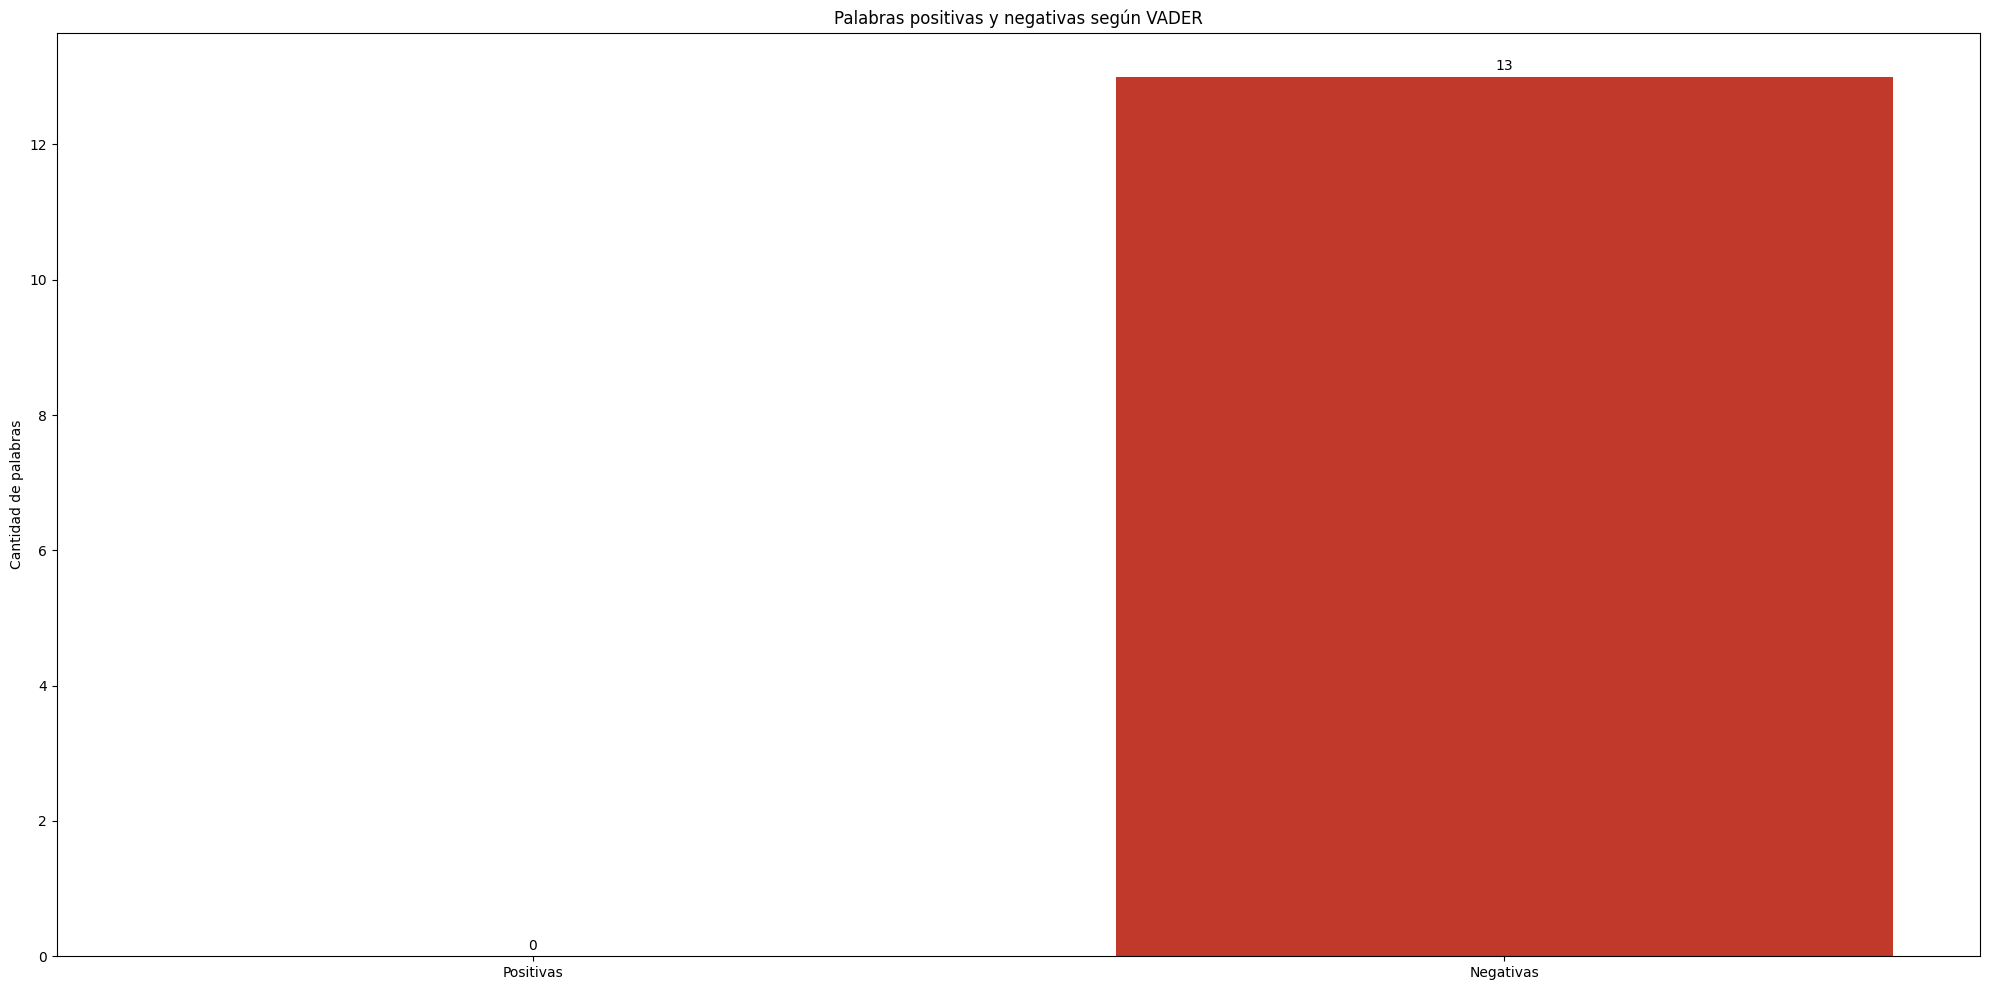

In [11]:
plt.figure(figsize=(20, 10))
barras = plt.bar(
    ["Positivas", "Negativas"],
    [len(positivas), len(negativas)],
    color=["#2e8b57", "#c0392b"]
)

plt.title("Palabras positivas y negativas según VADER")
plt.ylabel("Cantidad de palabras")

for barra, valor in zip(barras, [len(positivas), len(negativas)]):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.1,
        str(valor),
        ha="center"
    )

plt.tight_layout()
plt.savefig("grafica_sentimiento_llorona.png", dpi=150)
plt.show()

# 7. Grafica palabras positivas y negativas

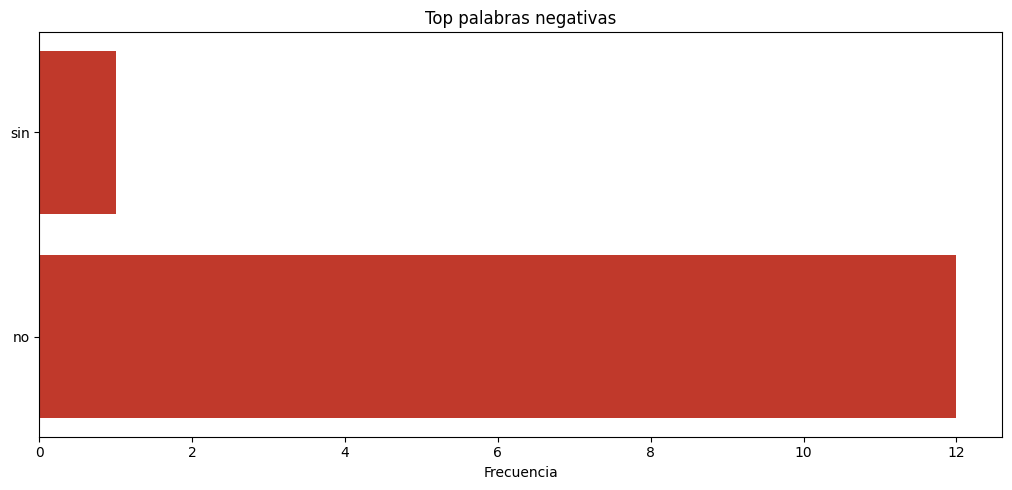

In [12]:
if positivas or negativas:
    top_pos = conteo_pos.most_common(10)
    top_neg = conteo_neg.most_common(10)

    plt.figure(figsize=(20, 5))

    if top_pos:
        plt.subplot(1, 2, 1)
        palabras_p, frec_p = zip(*top_pos)
        plt.barh(palabras_p, frec_p, color="#2e8b57")
        plt.title("Top palabras positivas")
        plt.xlabel("Frecuencia")

    if top_neg:
        plt.subplot(1, 2, 2)
        palabras_n, frec_n = zip(*top_neg)
        plt.barh(palabras_n, frec_n, color="#c0392b")
        plt.title("Top palabras negativas")
        plt.xlabel("Frecuencia")

    plt.tight_layout()
    plt.savefig("top_palabras_sentimiento_llorona.png", dpi=150)
    plt.show()

# 8. Tokenización y filtrado de stopwords en español 

In [13]:
import re
import pandas as pd
import nltk
from nltk.stem import SnowballStemmer
from nltk.corpus import stopwords

palabras = re.findall(r"\b[a-zA-záéíóúÁÉÍÓÚñÑ]+\b", texto.lower())

try:
    stop_words_es = set(stopwords.words('spanish'))
except LookupError:
    nltk.download('stopwords', quiet=True)
    from nltk.corpus import stopwords
    stop_words_es = set(stopwords.words('spanish'))

palabras_limpias = [w for w in palabras if w not in stop_words_es and len(w) > 2]

print(palabras_limpias)

['leyenda', 'mexicana', 'llorona', 'hace', 'muchísimos', 'años', 'ciudad', 'mexicana', 'llamada', 'xochimilco', 'gente', 'decía', 'escuchar', 'lamentos', 'extraña', 'mujer', 'dónde', 'hijos', 'dónde', 'hijooooos', 'decía', 'vez', 'aquellos', 'lamentos', 'extraños', 'quitaban', 'sueño', 'habitantes', 'zona', 'punto', 'sonaban', 'preferían', 'encerrarse', 'casas', 'salir', 'día', 'siguiente', 'podemos', 'gritos', 'podemos', 'dormir', 'gritaba', 'vecino', 'mañana', 'encontrarse', 'vecino', 'único', 'igual', 'dicen', 'mundo', 'encierra', 'cal', 'canto', 'comienzan', 'sonar', 'llantos', 'respondió', 'rumores', 'pueblos', 'ciudades', 'habituales', 'antaño', 'decía', 'aquellos', 'lamentos', 'tan', 'terribles', 'pertenecían', 'señora', 'iba', 'vestida', 'blanco', 'cabellos', 'largos', 'oscuros', 'iban', 'allá', 'atrevían', 'asegurar', 'misteriosa', 'mujer', 'caminaba', 'sino', 'ropajes', 'blancos', 'parecidos', 'antiquísimo', 'traje', 'novia', 'camisón', 'duda', 'parecían', 'volar', 'solo', 'v

# 9. STEMMING

In [14]:
stemmer_es = SnowballStemmer('spanish')
stems = [stemmer_es.stem(w) for w in palabras_limpias]

print(stems)

['leyend', 'mexican', 'lloron', 'hac', 'muchis', 'años', 'ciud', 'mexican', 'llam', 'xochimilc', 'gent', 'dec', 'escuch', 'lament', 'extrañ', 'muj', 'dond', 'hij', 'dond', 'hijoooo', 'dec', 'vez', 'aquell', 'lament', 'extrañ', 'quit', 'sueñ', 'habit', 'zon', 'punt', 'son', 'pref', 'encerr', 'cas', 'sal', 'dia', 'siguient', 'pod', 'grit', 'pod', 'dorm', 'grit', 'vecin', 'mañan', 'encontr', 'vecin', 'unic', 'igual', 'dic', 'mund', 'encierr', 'cal', 'cant', 'comienz', 'son', 'llant', 'respond', 'rumor', 'puebl', 'ciudad', 'habitual', 'antañ', 'dec', 'aquell', 'lament', 'tan', 'terribl', 'pertenec', 'señor', 'iba', 'vest', 'blanc', 'cabell', 'larg', 'oscur', 'iban', 'alla', 'atrev', 'asegur', 'misteri', 'muj', 'camin', 'sin', 'ropaj', 'blanc', 'parec', 'antiquisim', 'traj', 'novi', 'camison', 'dud', 'parec', 'vol', 'sol', 'vecin', 'dec', 'grit', 'agit', 'braz', 'señal', 'quej', 'angusti', 'asi', 'desaparec', 'brev', 'espaci', 'tiemp', 'recorr', 'extrañ', 'muj', 'casi', 'siempr', 'mism', 'i

# 10. Lematización 

In [15]:
!python -m spacy download es_core_news_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 53.2 MB/s eta 0:00:0000:0100:01
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [16]:
import spacy

nlp = spacy.load("es_core_news_sm")

doc = nlp(" ".join(palabras_limpias))
lemas = [token.lemma_ for token in doc]

print(lemas)

['leyenda', 'mexicano', 'lloronar', 'hacer', 'muchísimos', 'año', 'ciudad', 'mexicano', 'llamado', 'xochimilco', 'gente', 'decir', 'escuchar', 'lamento', 'extrañar', 'mujer', 'dónde', 'hijo', 'dónde', 'hijooooos', 'decir', 'vez', 'aquel', 'lamento', 'extraño', 'quitar', 'sueño', 'habitante', 'zona', 'punto', 'sonar', 'preferir', 'encerrar él', 'casa', 'salir', 'día', 'siguiente', 'poder', 'grito', 'poder', 'dormir', 'gritar', 'vecino', 'mañana', 'encontrar él', 'vecino', 'único', 'igual', 'decir', 'mundo', 'encerrar', 'cal', 'canto', 'comenzar', 'sonar', 'llanto', 'responder', 'rumor', 'pueblo', 'ciudad', 'habitual', 'antaño', 'decir', 'aquel', 'lamento', 'tanto', 'terrible', 'pertenecer', 'señora', 'ir', 'vestido', 'blanco', 'cabello', 'largo', 'oscuro', 'ir', 'allá', 'atrevir', 'asegurar', 'misterioso', 'mujer', 'caminar', 'sino', 'ropaj', 'blanco', 'parecido', 'antiquísimo', 'traje', 'novia', 'camisón', 'duda', 'parecer', 'volar', 'solo', 'vecino', 'decir', 'gritar', 'agitar', 'braz

# 11. Dataframe final

In [17]:
df_vocabulario = pd.DataFrame({
    'Palabra_Original': palabras_limpias,
    'Stemming_Raiz': stems,
    'Lematizacion': lemas
}).drop_duplicates(subset=['Palabra_Original']).reset_index(drop=True)

print(f"Total de palabras procesadas: {len(palabras_limpias)}")
print(f"Vocabulario único: {len(df_vocabulario)}\n")

display(df_vocabulario.sample(15))

Total de palabras procesadas: 280
Vocabulario único: 213



,Palabra_Original,Stemming_Raiz,Lematizacion
192,romper,romp,romper
40,único,unic,único
95,espacio,espaci,espacio
145,podía,pod,poder
0,leyenda,leyend,leyenda
72,sino,sin,sino
189,origen,orig,origen
100,mismo,mism,mismo
143,cómo,com,cómo
148,dolor,dolor,dolor
